In [38]:
%load_ext autoreload
%autoreload 1

%aimport highlighting_precision
%aimport gradcam_APs
%aimport gradcam
%aimport vanilla_vgg
%aimport dataHelper
%aimport external

import warnings
from torch.serialization import SourceChangeWarning
warnings.filterwarnings("ignore", category=SourceChangeWarning)

%matplotlib inline
!nvidia-smi

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Wed Jan 22 15:45:01 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.127.08             Driver Version: 550.127.08     CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla P100-PCIE-12GB           Off |   00000000:02:00.0 Off |                    0 |
| N/A   30C    P0             29W /  250W |    4823MiB /  12288MiB |      0%      Default |
|                                         |         

In [39]:
# Determine Device from Above
import torch
torch.cuda.set_device(os.environ['TORCH_DEVICE'])

In [40]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ext = external.ExternalValidationContext(
    environment = 'embed-open-data',
    external_validation_path=Path(os.environ['EXTERNAL_VAL_ROOT']),
    data_path=Path(os.environ['EMBED_OPEN_DATA_NP_DIR']) / 'one_roi',
    models=['iaia-bl', 'protopnet',  'vgg16'],
    margin_name_labels = [
        (0, 'circ_prob', 'circumscribed'),
        (1, 'indst_prob', 'indistinct'),
        (2, 'spic_prob', 'spiculated')
    ],
    malignancy_name_labels = [
        (0, 'mal_neg_prob', 'not_malignant'),
        (1, 'mal_pos_prob', 'malignant')
    ],
    subgroupings  = [
        ('all', 'all'), 
        ('manufacturer', 'ge'), ('manufacturer', 'hologic'),
        ('age_3_bucket', '<50'), ('age_3_bucket','50-69'), ('age_3_bucket', '>70'),
        ('age_2_bucket', '<=57'), ('age_2_bucket','>57'),
        ('race', 'Black or African American'), ('race', 'Caucasian/White'), ('race', 'Other/Unknown'),
        ('ethnicity', 'Hispanic or Latino'), ('ethnicity', 'Not Hispanic or Latino')
    ]
)

ext

ExternalValidationContext(environment=embed-open-data,
 models=['iaia-bl', 'protopnet', 'vgg16'],
 external_validation_path=/home/users/lam135/code/mammo/iaia-bl-ext,
 data_path=/usr/xtmp/lam135/iaiabl-ext/eod/np/one_roi,
 margin_name_labels=[(0, 'circ_prob', 'circumscribed'), (1, 'indst_prob', 'indistinct'), (2, 'spic_prob', 'spiculated')],
 malignancy_name_labels=[(0, 'mal_neg_prob', 'not_malignant'), (1, 'mal_pos_prob', 'malignant')],
 vanilla_vgg_path=/home/users/lam135/code/mammo/iaia-bl-ext/models/0.9504818324659497_at_epoch_60_corrected_format,
 protopnet_path=/home/users/lam135/code/mammo/iaia-bl-ext/models/50_5push0.9209.pth,
 iaiabl_path=/home/users/lam135/code/mammo/iaia-bl-ext/models/50_4push0.9546.pth,
 bb_malig_path=/home/users/lam135/code/mammo/iaia-bl-ext/models/0.8701298701298701_at_epoch_16_corrected_format,
 subgroupings=[('all', 'all'), ('manufacturer', 'ge'), ('manufacturer', 'hologic'), ('age_3_bucket', '<50'), ('age_3_bucket', '50-69'), ('age_3_bucket', '>70'), (

# Load Emory Metadata

In [41]:
basepath = Path(os.environ['EMBED_OPEN_DATA_TABLE_DIR'])
KEY_COLUMNS_MAG = ['Unnamed: 0', 'empi_anon', 'acc_anon', 'side', 'numfind', 'desc', 'asses']
KEY_COLUMNS_MET = ['Unnamed: 0', 'empi_anon', 'acc_anon', 'ImageLateralityFinal', 'ViewPosition', 'FinalImageType', 'AcquisitionTime']
CONTEXT_COLUMNS = ['cohort_num', 'study_date_anon']

__birads_map = {
    'A': 0,
    'N': 1,
    'B': 2,   
    'P': 3,
    'S': 4,
    'M': 5,
    'K': 6,
    'X': 'X'
}
    # BIRADS 0: A – Additional evaluation
    # BIRADS 1: N – Negative
    # BIRADS 2: B - Benign
    # BIRADS 3: P – Probably benign
    # BIRADS 4: S – Suspicious
    # BIRADS 5: M- Highly suggestive of malignancy
    # BIRADS 6: K - Known biopsy proven

def translate_birads(hiti_asses):
    return __birads_map[hiti_asses]


def lead_with_columns(df, lead_columns):
    """
    Rearranges dataframe column order by pulling a few columns to the front but keeping the order for other columns
    """
    post_columns = [col for col in df.columns if col not in lead_columns]
    return df[lead_columns + post_columns]

def load_met(file_path=os.path.join(basepath, 'EMBED_OpenData_metadata.csv'), 
            scope='min', extra_cols=[], cohorts=None, nrows=None):
    
    force_string_cols = ['CollimatorShape', '0_ProcedureCodeSequence_CodeValue', 'DerivationDescription',
                        'CommentsOnRadiationDose', 'DetectorDescription', 'WindowCenter', 'WindowWidth']
    
    categorical_cols = ['AcquisitionDeviceProcessingCode', 'AcquisitionDeviceProcessingDescription',
                        'DetectorConfiguration', 'FieldOfViewShape', 'CollimatorShape',
                        'DetectorActiveShape', 'ExposureStatus', 'VOILUTFunction'
                        '0_IconImageSequence_PhotometricInterpretation']
    
    tuple_cols = ['FieldOfViewDimensions', 'DetectorActiveDimensions', 'DetectorElementPhysicalSize',
                'DetectorElementSpacing', 'WindowCenterWidthExplanation']
    
    date_cols = ['study_date_anon']
    
    forced_types = {col: 'string' for col in force_string_cols}
    forced_types.update({col: 'category' for col in categorical_cols})
    forced_types.update({col: 'string' for col in tuple_cols})
    
    if scope == 'min':
        usecols = (KEY_COLUMNS_MET + CONTEXT_COLUMNS + 
                    ['png_path', 'png_filename', 'num_roi', 'ROI_coords', 'match_level', 'spot_mag'] + extra_cols)
    
    elif scope == 'full':
        usecols = None
    
    else:
        return NotImplemented(f'{scope} is not a valid column scope')
    
    df_metadata = pd.read_csv(file_path, dtype=forced_types, parse_dates=date_cols, usecols=usecols, nrows=nrows)
    
    if cohorts:
        df_metadata = df_metadata.loc[df_metadata['cohort_num'].isin(cohorts)]

    return df_metadata.pipe(lead_with_columns, KEY_COLUMNS_MET + CONTEXT_COLUMNS)

def load_mag(file_path=basepath/'EMBED_OpenData_clinical.csv', scope = 'min', extra_cols=[], cohorts=None):
    # columns that have inconsistent value types - default casting doesn't work properly
    inconsistent_columns = ['case', 'biopsite', 'bcomp', 'path7', 'path8', 'path9', 'path10', 'hgrade',
                            'tnmpt', 'tnmpn', 'tnmm', 'tnmdesc', 'stage', 'bdepth','focality',
                            'specinteg', 'specembed', 'her2', 'fish', 'extracap', 'methodevl',
                            'eic', 'first_3_zip']
    type_overrides = {col: 'string' for col in inconsistent_columns}

    categories = ['massshape', 'massmargin', 'massdens', 'calcfind', 'calcdistri', 'otherfind', 
                'implanfind', 'side', 'location', 'depth', 'distance', 'asses', 'recc', 'proccode',
                'vtype','tissueden', 'MARITAL_STATUS_DESC']
    type_overrides.update({col: 'category' for col in categories})

    date_cols = {'study_date_anon','sdate_anon','procdate_anon','pdate_anon'}
    
    if scope == 'min':
        usecols = (KEY_COLUMNS_MAG + CONTEXT_COLUMNS + ['ETHNIC_GROUP_DESC', 'ETHNICITY_DESC', 'age_at_study'] +
            ['massshape', 'massmargin', 'massdens', 'otherfind', 'path_group', 'path_severity'] + extra_cols)
        date_cols = date_cols.intersection(usecols)
        
    elif scope == 'full':
        usecols = None
        
    else:
        return NotImplemented(f'{scope} is not a valid column scope')
    
    df_mag =  pd.read_csv(file_path, header=0,usecols=usecols)
    
    df_mag['scr_or_diag'] = df_mag['desc'].apply(lambda desc: 'S' if 'screen' in desc.lower() else 'D').astype("category")
    df_mag['birads'] = df_mag['asses'].apply(translate_birads)

    if cohorts:
        df_mag = df_mag.loc[df_mag['cohort_num'].isin(cohorts)]

    return df_mag.pipe(lead_with_columns, KEY_COLUMNS_MAG + CONTEXT_COLUMNS)

# Emory Validation

## Activation Precision
These just setup the run and get preliminary results (n<<100). See the Export section below for n=100.

### GradCAM for VGG16

In [42]:
gradcam_aps = ext.run_gradcams(num_bootstraps=3)
gradcam_aps.pipe(display)
gradcam_aps.groupby(['method']).mean().pipe(display)

# Note that bootstraps may exclude individual classes for this sampling
# This is handled by volume in export

('1.2.826.0.1.3680043.8.498.75128353779097001475536884528240962686.dcm.png_0',) torch.Size([1, 4, 224, 224]) torch.Size([1])
torch_img torch.Size([1, 3, 224, 224])
### USUAL VGG MODEL ###
saliency_map size : torch.Size([14, 14])
saliency_map size : torch.Size([14, 14])
saliency_map size : torch.Size([112, 112])
saliency_map size : torch.Size([112, 112])
saliency_map size : torch.Size([112, 112])
saliency_map size : torch.Size([112, 112])
saliency_map size : torch.Size([14, 14])
saliency_map size : torch.Size([14, 14])


/usr/xtmp/lam135/conda/iaia-bl-ext/lib/python3.7/site-packages/torch/nn/functional.py:2390: UserWarning: nn.functional.upsample is deprecated. Use nn.functional.interpolate instead.
  warnings.warn("nn.functional.upsample is deprecated. Use nn.functional.interpolate instead.")


saving image to /home/users/lam135/code/mammo/iaia-bl-ext/grad_cam/one_roi-tmp.png
fine-scale activation precision for gradCAM is:  [(0, 0.7022651996886038), (1, 0.5877310719702075), (2, 1.0)]
fine-scale activation precision for gradCAM++ is:  [(0, 0.8687961192861893), (1, 0.8607728031242154), (2, 0.7340374463770484)]
lesion-scale activation precision for gradCAM is:  [(0, 0.7022651996886037), (1, 0.5877310719702075), (2, 1.0)]
lesion-scale activation precision for gradCAM++ is:  [(0, 0.8687961192861893), (1, 0.8607728031242154), (2, 0.7340374463770484)]
for data in /usr/xtmp/lam135/iaiabl-ext/eod/np/one_roi
Completed 1 samples. 
Final mean GradCAM AP Class 0 is 0.6937910816234699, std 0.06579781097357447 95.0% confidence iterval accuracy is 0.6100672592465891 to 0.7588602770471444 with 3 iterations.
Final mean GradCAM AP Class 1 is 0.5255426826309212, std 0.07624284038659929 95.0% confidence iterval accuracy is 0.4264334263688358 to 0.5927732103059192 with 3 iterations.
Final mean Gra

,ap,ci_025,ci_975,method,margin,model,num_bootstraps
0,0.693791,0.610067,0.758860,gradcam,circumscribed,vgg16,3
0,0.525543,0.426433,0.592773,gradcam,indistinct,vgg16,3
0,1.000000,NaN,NaN,gradcam,spiculated,vgg16,3
0,0.900650,0.835819,0.950580,gradcam++,circumscribed,vgg16,3
0,0.905738,0.760588,0.997892,gradcam++,indistinct,vgg16,3
0,0.734037,NaN,NaN,gradcam++,spiculated,vgg16,3


,ap,ci_025,ci_975,num_bootstraps
method,,,,
gradcam,0.739778,0.518250,0.675817,3
gradcam++,0.846808,0.798203,0.974236,3


### ProtoPNets

In [43]:
protopnets_aps = ext.classwise_activation_precision_for_protopnets(num_bootstraps=1, bootstrap_force_all_classes=True)
protopnets_aps.pipe(display)
protopnets_aps.groupby(['model']).mean().pipe(display)

iaia-bl -------------
protopnet -------------


/usr/xtmp/lam135/conda/iaia-bl-ext/lib/python3.7/site-packages/scipy/stats/_distn_infrastructure.py:1983: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/usr/xtmp/lam135/conda/iaia-bl-ext/lib/python3.7/site-packages/scipy/stats/_distn_infrastructure.py:1984: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


,ap,ci_025,ci_975,model,margin,num_bootstraps
0,1.000000,NaN,NaN,iaia-bl,circumscribed,1
0,1.000000,1.000000,1.000000,iaia-bl,indistinct,1
0,1.000000,NaN,NaN,iaia-bl,spiculated,1
0,0.927375,0.878985,0.975764,protopnet,circumscribed,1
0,0.598267,0.378782,0.817753,protopnet,indistinct,1
0,0.772523,0.235031,1.310016,protopnet,spiculated,1


,ap,ci_025,ci_975,num_bootstraps
model,,,,
iaia-bl,1.000000,1.000000,1.000000,1
protopnet,0.766055,0.497599,1.034511,1


# Model Predictions
## Margin Predictions

In [44]:
margin_predictions = ext.margin_predictions_for_models(image_has_rois=True)
margin_predictions['image'] = margin_predictions['patient_id'].str.split('_', 0, expand=True)[0]
margin_predictions = margin_predictions.drop('patient_id', axis=1)
margin_predictions.to_csv(ext.external_validation_path/f'{ext.environment}_margin_predictions.csv', index=False)
margin_predictions.groupby('model_name').count()

protopnet -------------


3it [00:00,  4.93it/s]

iaia-bl -------------



3it [00:00,  4.37it/s]


vgg16 -------------


3it [00:00,  3.69it/s]


,circ_logit,circ_prob,context_size,indst_logit,indst_prob,mal_neg_prob,mal_pos_prob,margin,margin_label,spic_logit,spic_prob,image
model_name,,,,,,,,,,,,
iaia-bl,19,19,19,19,19,0,0,19,19,19,19,19
protopnet,19,19,19,19,19,0,0,19,19,19,19,19
vgg16,0,19,19,0,19,19,19,19,19,0,19,19


In [45]:
__prob_sums = margin_predictions[['circ_prob', 'indst_prob', 'spic_prob']].sum(axis=1).round(2).value_counts()
assert len(__prob_sums) == 1 and 1.0 in __prob_sums
__prob_sums

1.0    57
dtype: int64

### Analyze Results

In [46]:
margin_predictions = pd.read_csv(ext.external_validation_path/f'{ext.environment}_margin_predictions.csv')
margin_predictions.groupby('model_name').apply(lambda group: group.sample(2))

circ_logit     circ_prob  context_size  indst_logit  \
model_name                                                           
iaia-bl    29  -13.253499  8.284642e-10           100    -6.390273   
           20   -9.126972  2.835048e-08           100     8.251642   
protopnet  18   -8.377705  1.540117e-03           100    -1.906618   
           16   -9.161404  2.579009e-03           100    -3.246415   
vgg16      53         NaN  3.902806e-01           100          NaN   
           51         NaN  8.116542e-01           100          NaN   

                 indst_prob  mal_neg_prob  mal_pos_prob         margin  \
model_name                                                               
iaia-bl    29  7.923825e-07           NaN           NaN     spiculated   
           20  9.999924e-01           NaN           NaN  circumscribed   
protopnet  18  9.952010e-01           NaN           NaN  circumscribed   
           16  9.556515e-01           NaN           NaN  circumscribed   
vgg16      53  5.407013e-01      0.411892      0.588108  circumscribed   
           51  1.560602e-01      0.988082      0.011919  circumscribed   

               margin_label model_name  spic_logit  spic_prob  \
model_name                                                      
iaia-bl    29             2    iaia-bl    7.657948   0.999999   
           20             0    iaia-bl   -3.511262   0.000008   
protopnet  18             0  protopnet   -7.628196   0.003259   
           16             0  protopnet   -6.376644   0.041769   
vgg16      53             0      vgg16         NaN   0.069018   
           51             0      vgg16         NaN   0.032286   

                                                           image  
model_name                                                        
iaia-bl    29  1.2.826.0.1.3680043.8.498.96659188332139861480...  
           20  1.2.826.0.1.3680043.8.498.28354116783075941866...  
protopnet  18  1.2.826.0.1.3680043.8.498.46466915575536134608...  
           16  1.2.826.0.1.3680043.8.498.26310411707660872670...  
vgg16      53  1.2.826.0.1.3680043.8.498.50003052663038348729...  
           51  1.2.826.0.1.3680043.8.498.10761033670449944220...

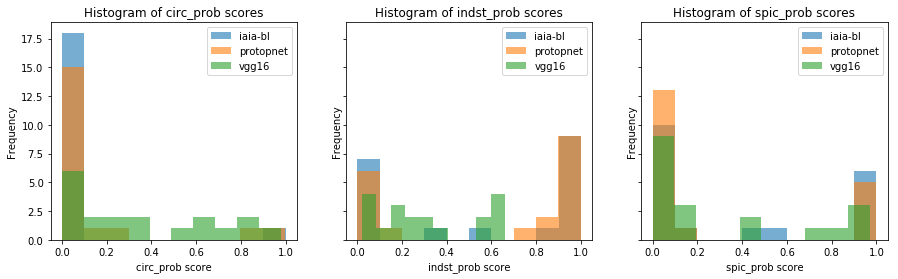

In [47]:
ext.plot_margin_probs(margin_predictions)

# Data Augmentation
Needed for malignancy prediction

In [48]:
label_file = Path(os.environ['EMBED_OPEN_DATA_NP_DIR'])/'one_roi'/'index.csv'
df_met_4path = pd.read_csv(label_file)
print(df_met_4path.shape)
df_met_4path = df_met_4path[['empi_anon', 'acc_anon_scr', 'acc_anon_diag', 'roi_np_paths', 'ImageLateralityFinal', 'Manufacturer', 'worst_path_severity']]
df_met_4path['image'] = df_met_4path['roi_np_paths'].str.split('/').str[-1].str[:-6]
df_met_4path['acc_anon_scr'].unique().shape

(19, 795)


(10,)

In [49]:
mag = load_mag(extra_cols=['ETHNICITY_DESC', 'ETHNIC_GROUP_DESC'])
mag.head()

,Unnamed: 0,empi_anon,acc_anon,side,numfind,desc,asses,cohort_num,study_date_anon,massshape,massmargin,massdens,otherfind,ETHNICITY_DESC,ETHNIC_GROUP_DESC,age_at_study,path_group,path_severity,scr_or_diag,birads
0,117,60696029,8099128854014801,R,1,MG Diagnostic Right,A,1,2013-12-30,S,D,NaN,NaN,African American or Black,"Unreported, Unknown, Unavailable",69.652354,NaN,NaN,D,0
1,124,90986305,5156106114290009,L,1,MG Diagnostic Left,P,1,2013-08-26,F,NaN,NaN,NaN,African American or Black,"Unreported, Unknown, Unavailable",42.741466,NaN,NaN,D,3
2,126,78097721,3065491565033830,NaN,1,MG Screening Bilateral w/CAD,N,1,2013-02-19,NaN,NaN,NaN,NaN,Caucasian or White,Non-Hispanic or Latino,60.967713,NaN,NaN,S,1
3,128,43734324,1878527667143380,R,1,MG Screening Bilateral w/CAD,A,1,2013-02-08,NaN,NaN,NaN,NaN,African American or Black,Non-Hispanic or Latino,56.329699,2.0,2.0,S,0
4,129,28410573,8493926076199113,B,1,MG Screening Bilateral w/CAD,B,1,2013-02-18,O,U,NaN,NaN,Asian,Non-Hispanic or Latino,50.544501,NaN,NaN,S,2


In [50]:
mag['empi_anon'].nunique()

23253

In [51]:
# Adding in columns for race and age
df_met_4path_wmag = df_met_4path.merge(mag, left_on=['empi_anon', 'acc_anon_scr', 'ImageLateralityFinal'], right_on=['empi_anon', 'acc_anon', 'side'])
df_met_4path_wmag = df_met_4path_wmag[['empi_anon', 'acc_anon_scr', 'acc_anon_diag', 'image', 'side', 'numfind', 'asses', 'cohort_num', 'path_group', 'path_severity', 'scr_or_diag', 'birads', 'Manufacturer', 'worst_path_severity']]
df_met_4path_wmag.head()

,empi_anon,acc_anon_scr,acc_anon_diag,image,side,numfind,asses,cohort_num,path_group,path_severity,scr_or_diag,birads,Manufacturer,worst_path_severity
0,87044212,5668256162356485,4087961856575134,1.2.826.0.1.3680043.8.498.75128353779097001475...,R,1,A,1,4.0,4.0,S,0,"HOLOGIC, Inc.",4.0
1,20342368,3621558600062267,8260533751268032,1.2.826.0.1.3680043.8.498.46466915575536134608...,L,1,A,1,4.0,4.0,S,0,"HOLOGIC, Inc.",4.0
2,20342368,3621558600062267,8260533751268032,1.2.826.0.1.3680043.8.498.28354116783075941866...,L,1,A,1,4.0,4.0,S,0,"HOLOGIC, Inc.",4.0
3,19580739,6994066911079308,9867091834064192,1.2.826.0.1.3680043.8.498.35086967959064398345...,R,1,A,2,NaN,NaN,S,0,"HOLOGIC, Inc.",4.0
4,19580739,6994066911079308,9867091834064192,1.2.826.0.1.3680043.8.498.12173593006071682875...,R,1,A,2,NaN,NaN,S,0,"HOLOGIC, Inc.",4.0


In [52]:
margin_predictions['image'][0], df_met_4path_wmag['image'][0]

('1.2.826.0.1.3680043.8.498.10093274451287205105397682181269434149.dcm.png',
 '1.2.826.0.1.3680043.8.498.75128353779097001475536884528240962686.dcm.png')

In [53]:
margin_pred_wlabels_df = margin_predictions.merge(df_met_4path_wmag, left_on='image', right_on='image')

assert margin_pred_wlabels_df.shape[0] == margin_pred_wlabels_df['image'].nunique() * 3
margin_pred_wlabels_df.head(2).pipe(display)
margin_pred_wlabels_df.shape[0]

,circ_logit,circ_prob,context_size,indst_logit,indst_prob,mal_neg_prob,mal_pos_prob,margin,margin_label,model_name,...,side,numfind,asses,cohort_num,path_group,path_severity,scr_or_diag,birads,Manufacturer,worst_path_severity
0,-4.771848,0.888037,100,-6.882575,1.075857e-01,NaN,NaN,circumscribed,0,protopnet,...,R,1,A,2,NaN,NaN,S,0,"HOLOGIC, Inc.",4.0
1,7.860914,1.000000,100,-9.307888,3.496906e-08,NaN,NaN,circumscribed,0,iaia-bl,...,R,1,A,2,NaN,NaN,S,0,"HOLOGIC, Inc.",4.0


57

In [54]:
mass_uid = (margin_pred_wlabels_df['image'].astype(str) + margin_pred_wlabels_df['side'])
mass_uid.nunique(), margin_pred_wlabels_df['acc_anon_scr'].shape

(19, (57,))

In [55]:
score_label_df = margin_pred_wlabels_df.merge(mag, left_on=['empi_anon', 'acc_anon_scr', 'side'], right_on=['empi_anon', 'acc_anon', 'side'])
display(score_label_df.shape)
score_label_df.head()

(57, 44)

,circ_logit,circ_prob,context_size,indst_logit,indst_prob,mal_neg_prob,mal_pos_prob,margin,margin_label,model_name,...,massmargin,massdens,otherfind,ETHNICITY_DESC,ETHNIC_GROUP_DESC,age_at_study,path_group_y,path_severity_y,scr_or_diag_y,birads_y
0,-4.771848,8.880373e-01,100,-6.882575,1.075857e-01,NaN,NaN,circumscribed,0,protopnet,...,D,=,NaN,Caucasian or White,Non-Hispanic or Latino,62.030021,NaN,NaN,S,0
1,7.860914,1.000000e+00,100,-9.307888,3.496906e-08,NaN,NaN,circumscribed,0,iaia-bl,...,D,=,NaN,Caucasian or White,Non-Hispanic or Latino,62.030021,NaN,NaN,S,0
2,NaN,9.779881e-01,100,NaN,2.143790e-02,0.992074,0.007926,circumscribed,0,vgg16,...,D,=,NaN,Caucasian or White,Non-Hispanic or Latino,62.030021,NaN,NaN,S,0
3,-6.626945,3.189638e-02,100,-13.646227,2.853026e-05,NaN,NaN,circumscribed,0,protopnet,...,D,=,NaN,Caucasian or White,Non-Hispanic or Latino,62.030021,NaN,NaN,S,0
4,-12.892715,1.129208e-09,100,-8.369379,1.040479e-07,NaN,NaN,circumscribed,0,iaia-bl,...,D,=,NaN,Caucasian or White,Non-Hispanic or Latino,62.030021,NaN,NaN,S,0


In [56]:
margin_pred_wlabels_df['Manufacturer'].unique()

array(['HOLOGIC, Inc.'], dtype=object)

In [57]:
score_label_df['mass_uid'] = score_label_df['image'] + score_label_df['side']
score_label_df['image_id'] = score_label_df['image']
score_label_df['patient_id'] = score_label_df['empi_anon']

def clean_manufacturer(manufacturer):
    if manufacturer == 'HOLOGIC, Inc.':
        return 'hologic'
    else:
        raise ValueError(manufacturer)

def clean_race(row):
    race, ethnicity = row['ETHNICITY_DESC'], row['ETHNIC_GROUP_DESC']
    # TODO - check these labels
    if race == 'African American  or Black':
        return 'Black or African American'
    elif race == 'Caucasian or White':
        return 'Caucasian/White'
    elif race in ('Unknown, Unavailable or Unreported', 'Asian', 'Native Hawaiian or Other Pacific Islander', 'American Indian or Alaskan Native'):
        return 'Other/Unknown'
    else:
        raise ValueError(race)

score_label_df['race'] = score_label_df[['ETHNICITY_DESC', 'ETHNIC_GROUP_DESC']].apply(clean_race, axis=1)
score_label_df['ethnicity'] = score_label_df['ETHNIC_GROUP_DESC']

score_label_df['age'] = score_label_df['age_at_study']
score_label_df['age_3_bucket'] = score_label_df['age_at_study'].apply(external.age_3_bucket)
score_label_df['age_2_bucket'] = score_label_df['age_at_study'].apply(external.age_2_bucket)

score_label_df['manufacturer_orig'] = score_label_df['Manufacturer']
score_label_df['manufacturer'] = score_label_df['manufacturer_orig'].apply(clean_manufacturer)

score_label_df[['ethnicity', 'race', 'age', 'age_2_bucket', 'age_3_bucket', 'manufacturer_orig', 'manufacturer']].head(3)

,ethnicity,race,age,age_2_bucket,age_3_bucket,manufacturer_orig,manufacturer
0,Non-Hispanic or Latino,Caucasian/White,62.030021,>57,50-69,"HOLOGIC, Inc.",hologic
1,Non-Hispanic or Latino,Caucasian/White,62.030021,>57,50-69,"HOLOGIC, Inc.",hologic
2,Non-Hispanic or Latino,Caucasian/White,62.030021,>57,50-69,"HOLOGIC, Inc.",hologic


In [58]:
path_severity_map = {
    0: "Invasive Cancer",
    1: "Non-Invasive Cancer",
    2: "High-Risk Lesion",
    3: "Borderline Lesion",
    4: "Benign Finding"
}

score_label_df['malignancy_label'] = score_label_df['worst_path_severity'].isin([0,1])

## Malignancy Prediction

In [59]:
## Add Malignancy Predictions
predictions_wmal = ext.malignancy_for_models(score_label_df)

predictions_wmal.groupby('model_name').count()[['mal_pos_prob', 'mal_neg_prob', 'malignancy_pred']]

,mal_pos_prob,mal_neg_prob,malignancy_pred
model_name,,,
iaia-bl,19,19,19
protopnet,19,19,19
vgg16,19,19,19


In [60]:
__prob_sums = predictions_wmal[['mal_pos_prob', 'mal_neg_prob']].sum(axis=1).round(2).value_counts()
assert len(__prob_sums) == 1 and 1.0 in __prob_sums
__prob_sums

1.0    57
dtype: int64

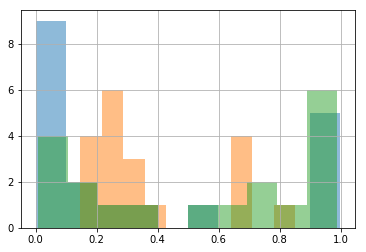

In [61]:
for model in ext.models:
    predictions_wmal[predictions_wmal['model_name'] == model]['mal_pos_prob'].hist(alpha=0.5)

# Analysis

## Logits (Unique to EMBED Open Data)

In [ ]:
predictions_for_export = predictions_wmal[['model_name', 'image', 'mal_pos_prob', 'malignancy_pred', 'malignancy_label', 'circ_logit', 'circ_prob', 'indst_logit', 'indst_prob', 'spic_logit', 'spic_prob', 'context_size', 'margin', 'margin_label']].set_index(['model_name', 'image']).sort_index()

predictions_for_export.head(3)

In [42]:
predictions_for_export.to_csv(ext.external_validation_path/f'{ext.environment}_logits.csv')

## Summary Statistics

In [ ]:
summary = ext.patient_summary_statistics(predictions_wmal)[['subgroup', 'value', 'count']]
# summary.to_csv(ext.external_validation_path/f'{ext.environment}_summary.csv')
summary

## ROC

In [ ]:
ext.roc_figure_for_models(predictions_wmal)

# Export Key Results

## Margin ROC

In [ ]:
export_df = predictions_wmal.copy()

In [ ]:
margin_roc_df, margin_ci_df = ext.roc_dfs(export_df, 'margin', ext.margin_name_labels, 'margin_label')
margin_roc_df.head(5).pipe(display)
margin_ci_df.head(5).pipe(display)

# Note the warnings come from the fact some subgroups don't exist in this subset. Obviously, that is not a valid test, but it's included for completeness.

In [ ]:
margin_roc_df.to_csv(ext.external_validation_path / f'{ext.environment}_margin_roc.csv', index=False)
margin_roc_df.groupby(['model', 'margin']).count().pipe(display)

margin_ci_df.to_csv(ext.external_validation_path / f'{ext.environment}_margin_ci.csv', index=False)
margin_ci_df[margin_ci_df['subgrouping'] == 'all'].pivot(index='margin', columns='model', values=['auc', 'ci_025', 'ci_975']).swaplevel(0,1,axis=1)[ext.models].round(2)

## Activation Precision

In [30]:
EXPORT_BOOTSTRAPS=100

In [ ]:
prototype_ap_df = ext.classwise_activation_precision_for_protopnets(num_bootstraps=EXPORT_BOOTSTRAPS, bootstrap_force_all_classes=True)
prototype_ap_df

In [ ]:
gradcam_ap_df = ext.run_gradcams(num_bootstraps=EXPORT_BOOTSTRAPS, bootstrap_force_all_classes=True)
gradcam_ap_df

In [ ]:
ap_ci_df = pd.concat([prototype_ap_df, gradcam_ap_df], sort=True)
ap_ci_df.to_csv(ext.external_validation_path / f'{ext.environment}_ap_ci.csv', index=False)
ap_ci_df.fillna('').groupby(['model', 'method']).mean().pipe(display)
ap_ci_df.pipe(display)

## Malignancy

In [34]:
export_df[['mal_pos_prob', 'malignancy_label', 'model_name']].to_csv(ext.external_validation_path/f'{ext.environment}_mal_dist.csv', index=False)

In [ ]:
mal_roc_df, mal_ci_df = ext.roc_dfs(export_df, 'malignancy', ext.malignancy_name_labels, 'malignancy_label')
mal_roc_df.pipe(display)
mal_ci_df.pipe(display)

In [ ]:
mal_roc_df.to_csv(ext.external_validation_path / f'{ext.environment}_mal_roc.csv', index=False)
mal_roc_df.groupby(['model', 'malignancy']).count().pipe(display)

mal_ci_df.to_csv(ext.external_validation_path / f'{ext.environment}_mal_ci.csv', index=False)
mal_ci_df[mal_ci_df['subgrouping'] == 'all']\
    .pivot(index='malignancy', columns='model', values=['auc', 'ci_025', 'ci_975'])\
    .swaplevel(0,1,axis=1)[ext.models].round(2)

# Note the warnings come from the fact some subgroups only have one entry in the class. Obviously, that is not a valid test, but it's included for completeness.

In [ ]:
plt.figure()

# Plot ROC curve for each class
for model in ext.models:
    class_data = mal_roc_df[(mal_roc_df['model'] == model) & (mal_roc_df['malignancy'] == 'malignant')].sort_values('threshold')

    row = mal_ci_df[(mal_ci_df['subgrouping'] == 'all') & (mal_ci_df['model'] == model) & (mal_ci_df['malignancy'] == 'malignant')].round(2)

    auc_label = f'AUC: {row["auc"].item()} ({row["ci_025"].item()}, {row["ci_975"].item()})'

    plt.plot(class_data['fpr'], class_data['tpr'], label=f'Model {model}\n{auc_label}')

plt.plot([0, 1], [0, 1],'--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Malignancy')
plt.legend(loc='best')

# Show the plot
plt.show()